# Experiment 08 — High-Performance Big Data Analytics Using R

**Name:** Sheshank Singh  
**Roll Number:** 23102A0017  
**Subject:** R Programming  


## Problem Statement

The New York City Taxi and Limousine Commission (NYC TLC) generates millions of taxi-trip records containing pickup and drop-off timestamps, locations, passenger counts, trip distance, fare, payment type and total amount. Processing such large datasets with conventional approaches can increase execution time and memory consumption.

The objective of this experiment is to build a scalable analytics workflow in R using the NYC Yellow Taxi Trip dataset. The experiment uses `data.table` for efficient data processing, compares functional and vectorized implementations, evaluates sequential and parallel processing, and benchmarks alternative approaches.

## Objectives

- Import, clean and prepare NYC Yellow Taxi Trip data.
- Join trip records with the official Taxi Zone Lookup Table.
- Analyse demand, revenue, routes, fare, distance and payment preferences.
- Compare base R, functional programming, vectorized operations and `data.table`.
- Compare sequential and parallel execution using `foreach` and `doParallel`.
- Measure execution time and calculate parallel speedup.
- Visualize important findings using `ggplot2`.
- Recommend suitable approaches based on measured results.

## Dataset Description

**Dataset:** NYC Taxi & Limousine Commission (TLC) — Yellow Taxi Trip Records  
**Official source:** [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)

This notebook downloads the January 2024 Yellow Taxi Trip Records in Parquet format and the official Taxi Zone Lookup Table.

## 1. Install and Load Required Packages

The packages below support Parquet data import, efficient data manipulation, visualization, functional programming, benchmarking and parallel processing.

In [30]:
packages <- c(
  "arrow",
  "data.table",
  "ggplot2",
  "foreach",
  "doParallel",
  "microbenchmark",
  "purrr",
  "lubridate"
)

installed <- rownames(installed.packages())
for (pkg in packages) {
  if (!pkg %in% installed) {
    install.packages(pkg, repos = "https://cloud.r-project.org")
  }
}

library(arrow)
library(data.table)
library(ggplot2)
library(foreach)
library(doParallel)
library(microbenchmark)
library(purrr)
library(lubridate)

cat("All required packages are loaded.\n")

All required packages are loaded.


## 2. Download the Taxi Dataset and Zone Lookup

The official TLC monthly Parquet file and zone lookup table are downloaded directly. If the files already exist in the session, they are reused.

In [2]:
trip_url <- "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
zone_url <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

trip_file <- "yellow_tripdata_2024-01.parquet"
zone_file <- "taxi_zone_lookup.csv"

if (!file.exists(trip_file)) {
  download.file(trip_url, trip_file, mode = "wb", quiet = FALSE)
}
if (!file.exists(zone_file)) {
  download.file(zone_url, zone_file, mode = "wb", quiet = FALSE)
}

cat("Trip file exists:", file.exists(trip_file), "\n")
cat("Zone lookup exists:", file.exists(zone_file), "\n")

Trip file exists: TRUE 
Zone lookup exists: TRUE 


## 3. Import and Inspect the Data

The Parquet file is read into R. A configurable sample limit helps control memory use in a hosted notebook environment.

In [3]:
MAX_ROWS <- 500000  # Change to Inf to retain the full monthly file if memory permits

trips_raw <- as.data.table(arrow::read_parquet(trip_file))
zones <- fread(zone_file)

cat("Rows in downloaded monthly file:", format(nrow(trips_raw), big.mark = ","), "\n")
cat("Columns:", ncol(trips_raw), "\n")

if (is.finite(MAX_ROWS) && nrow(trips_raw) > MAX_ROWS) {
  set.seed(123)
  trips <- trips_raw[sample.int(.N, MAX_ROWS)]
} else {
  trips <- copy(trips_raw)
}

cat("Rows selected for this experiment:", format(nrow(trips), big.mark = ","), "\n")
cat("Zone lookup rows:", nrow(zones), "\n")

Rows in downloaded monthly file: 2,964,624 
Columns: 19 
Rows selected for this experiment: 500,000 
Zone lookup rows: 265 


In [4]:
# Inspect the structure and data types
str(trips)

Classes ‘data.table’ and 'data.frame':	500000 obs. of  19 variables:
 $ VendorID             : int  2 2 2 2 2 2 2 2 1 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2024-01-23 18:08:56" "2024-01-02 20:25:01" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2024-01-23 18:15:46" "2024-01-02 20:49:11" ...
 $ passenger_count      : int  2 1 1 1 1 2 1 2 3 1 ...
 $ trip_distance        : num  0.53 13.11 1.76 1.72 1.61 ...
 $ RatecodeID           : int  1 1 1 1 1 1 1 3 1 1 ...
 $ store_and_fwd_flag   : chr  "N" "N" "N" "N" ...
 $ PULocationID         : int  237 132 186 114 166 48 238 161 4 142 ...
 $ DOLocationID         : int  237 252 229 234 43 163 90 1 264 142 ...
 $ payment_type         : int  1 2 1 1 1 1 1 2 1 1 ...
 $ fare_amount          : num  7.9 49.9 17.7 12.8 10.7 17.7 25.4 88.8 7.2 5.1 ...
 $ extra                : num  2.5 1 2.5 1 0 0 2.5 1 3.5 0 ...
 $ mta_tax              : num  0.5 0.5 0.5 0.5 0.5 0.5 0.5 0 0.5 0.5 ...
 $ tip_amount           : num  3.6 0 7.26 3.56 2.44 2 4 

In [5]:
# Dataset dimensions and summary statistics
dim(trips)
summary(trips)

[1] 500000     19

    VendorID     tpep_pickup_datetime            
 Min.   :1.000   Min.   :2002-12-31 22:59:39.00  
 1st Qu.:2.000   1st Qu.:2024-01-09 15:37:53.50  
 Median :2.000   Median :2024-01-17 10:55:11.00  
 Mean   :1.753   Mean   :2024-01-17 00:38:27.57  
 3rd Qu.:2.000   3rd Qu.:2024-01-24 18:38:53.75  
 Max.   :6.000   Max.   :2024-01-31 23:59:30.00  
                                                 
 tpep_dropoff_datetime            passenger_count trip_distance     
 Min.   :2002-12-31 23:05:41.00   Min.   :0.000   Min.   :    0.00  
 1st Qu.:2024-01-09 15:53:48.00   1st Qu.:1.000   1st Qu.:    1.00  
 Median :2024-01-17 11:13:40.50   Median :1.000   Median :    1.68  
 Mean   :2024-01-17 00:54:00.96   Mean   :1.338   Mean   :    3.34  
 3rd Qu.:2024-01-24 18:54:33.00   3rd Qu.:1.000   3rd Qu.:    3.13  
 Max.   :2024-02-01 22:04:34.00   Max.   :8.000   Max.   :33916.10  
                                  NA's   :23679                     
   RatecodeID     store_and_fwd_flag  PULocation

In [6]:
# Check missing values by column
missing_summary <- data.table(
  Column = names(trips),
  Missing_Count = vapply(trips, function(x) sum(is.na(x)), numeric(1))
)
missing_summary[order(-Missing_Count)]

Column,Missing_Count
<chr>,<dbl>
passenger_count,23679
RatecodeID,23679
store_and_fwd_flag,23679
congestion_surcharge,23679
Airport_fee,23679
VendorID,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
trip_distance,0


## 4. Data Cleaning and Feature Engineering

The cleaning process removes exact duplicate rows and records with invalid timestamps, negative/zero trip distance, invalid passenger counts, and non-positive total amounts. Some zero-passenger records may be valid in real data, so this notebook retains passenger counts from 0 to 6 and reports the cleaning effect. Temporal fields are extracted for hourly, weekday and monthly analysis.

In [7]:
# Standardize the data.table object and select useful columns
setDT(trips)

required_cols <- c(
  "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
  "passenger_count", "trip_distance", "RatecodeID",
  "PULocationID", "DOLocationID", "payment_type",
  "fare_amount", "tip_amount", "tolls_amount", "total_amount"
)
missing_cols <- setdiff(required_cols, names(trips))
if (length(missing_cols) > 0) {
  stop(paste("Expected columns missing:", paste(missing_cols, collapse = ", ")))
}
trips <- trips[, ..required_cols]

rows_before <- nrow(trips)
trips <- unique(trips)

trips[, tpep_pickup_datetime := as.POSIXct(tpep_pickup_datetime, tz = "UTC")]
trips[, tpep_dropoff_datetime := as.POSIXct(tpep_dropoff_datetime, tz = "UTC")]

trips_clean <- trips[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  tpep_dropoff_datetime >= tpep_pickup_datetime &
  !is.na(PULocationID) & !is.na(DOLocationID) &
  !is.na(trip_distance) & trip_distance > 0 &
  !is.na(fare_amount) & fare_amount > 0 &
  !is.na(total_amount) & total_amount > 0 &
  passenger_count >= 0 & passenger_count <= 6
]

cat("Rows before cleaning:", format(rows_before, big.mark = ","), "\n")
cat("Rows after cleaning:", format(nrow(trips_clean), big.mark = ","), "\n")
cat("Rows removed:", format(rows_before - nrow(trips_clean), big.mark = ","), "\n")

Rows before cleaning: 500,000 
Rows after cleaning: 464,531 
Rows removed: 35,469 


In [8]:
# Extract time-based features and calculate trip duration
trips_clean[, `:=`(
  pickup_hour = hour(tpep_pickup_datetime),
  pickup_day = day(tpep_pickup_datetime),
  pickup_weekday = wday(tpep_pickup_datetime, label = TRUE, abbr = FALSE, week_start = 1),
  pickup_month = month(tpep_pickup_datetime, label = TRUE, abbr = TRUE),
  trip_duration_min = as.numeric(difftime(
    tpep_dropoff_datetime, tpep_pickup_datetime, units = "mins"
  ))
)]

# Remove implausible duration values for analysis
trips_clean <- trips_clean[
  trip_duration_min >= 0 & trip_duration_min <= 360
]

# Retain only columns required for the rest of the analysis
trips_clean <- trips_clean[, .(
  tpep_pickup_datetime, tpep_dropoff_datetime,
  passenger_count, trip_distance, PULocationID, DOLocationID,
  payment_type, fare_amount, tip_amount, tolls_amount, total_amount,
  pickup_hour, pickup_day, pickup_weekday, pickup_month, trip_duration_min
)]

cat("Cleaned records available for analysis:", format(nrow(trips_clean), big.mark = ","), "\n")
head(trips_clean)

Cleaned records available for analysis: 464,266 


tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,tolls_amount,total_amount,pickup_hour,pickup_day,pickup_weekday,pickup_month,trip_duration_min
<dttm>,<dttm>,<int>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<ord>,<ord>,<dbl>
2024-01-23 18:08:56,2024-01-23 18:15:46,2,0.53,237,237,1,7.9,3.60,0,18.00,18,23,Tuesday,Jan,6.833333
2024-01-02 20:25:01,2024-01-02 20:49:11,1,13.11,132,252,2,49.9,0.00,0,54.15,20,2,Tuesday,Jan,24.166667
2024-01-31 16:57:30,2024-01-31 17:18:11,1,1.76,186,229,1,17.7,7.26,0,31.46,16,31,Wednesday,Jan,20.683333
2024-01-20 02:29:24,2024-01-20 02:40:23,1,1.72,114,234,1,12.8,3.56,0,21.36,2,20,Saturday,Jan,10.983333
2024-01-22 09:15:49,2024-01-22 09:24:15,1,1.61,166,43,1,10.7,2.44,0,14.64,9,22,Monday,Jan,8.433333
2024-01-06 19:23:01,2024-01-06 19:41:48,2,1.56,48,163,1,17.7,2.00,0,23.70,19,6,Saturday,Jan,18.783333


## 5. Integrate Taxi Zone Information

The Taxi Zone Lookup Table maps location IDs to zone names and boroughs. Two copies are joined to the trip data: one for pickup and one for drop-off locations.

In [9]:
zones_pickup <- copy(zones)
setnames(
  zones_pickup,
  old = c("LocationID", "Borough", "Zone"),
  new = c("PULocationID", "PU_Borough", "PU_Zone")
)

zones_dropoff <- copy(zones)
setnames(
  zones_dropoff,
  old = c("LocationID", "Borough", "Zone"),
  new = c("DOLocationID", "DO_Borough", "DO_Zone")
)

trips_joined <- merge(trips_clean, zones_pickup, by = "PULocationID", all.x = TRUE)
trips_joined <- merge(trips_joined, zones_dropoff, by = "DOLocationID", all.x = TRUE)

cat("Rows after zone joins:", format(nrow(trips_joined), big.mark = ","), "\n")
cat("Missing pickup zone names:", sum(is.na(trips_joined$PU_Zone)), "\n")
cat("Missing drop-off zone names:", sum(is.na(trips_joined$DO_Zone)), "\n")
head(trips_joined)

Rows after zone joins: 464,266 
Missing pickup zone names: 0 
Missing drop-off zone names: 0 


DOLocationID,PULocationID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,tolls_amount,⋯,pickup_day,pickup_weekday,pickup_month,trip_duration_min,PU_Borough,PU_Zone,service_zone.x,DO_Borough,DO_Zone,service_zone.y
<int>,<int>,<dttm>,<dttm>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<int>,<ord>,<ord>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1,2024-01-01 17:45:45,2024-01-01 17:50:13,1,0.01,1,110.0,27.75,0,⋯,1,Monday,Jan,4.46666667,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-25 13:07:20,2024-01-25 13:07:32,1,0.02,1,142.0,28.60,0,⋯,25,Thursday,Jan,0.20000000,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-21 08:46:54,2024-01-21 08:47:22,2,0.29,1,90.0,18.20,0,⋯,21,Sunday,Jan,0.46666667,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-18 18:48:04,2024-01-18 18:48:19,1,16.00,1,125.0,0.00,0,⋯,18,Thursday,Jan,0.25000000,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-03 08:00:05,2024-01-03 08:00:10,1,0.08,1,111.5,22.50,0,⋯,3,Wednesday,Jan,0.08333333,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR
1,1,2024-01-01 14:57:56,2024-01-01 14:58:47,4,0.01,1,20.0,0.00,0,⋯,1,Monday,Jan,0.85000000,EWR,Newark Airport,EWR,EWR,Newark Airport,EWR


## 6. Transportation Data Analytics

The following summaries examine taxi demand by hour and weekday, monthly usage, average fares, revenue, common routes, high-revenue routes and payment preferences. The results are calculated from the selected and cleaned records, not from the entire TLC archive.

In [10]:
# Number of trips by hour
trips_by_hour <- trips_joined[, .(
  Trips = .N,
  Average_Fare = mean(fare_amount, na.rm = TRUE),
  Total_Revenue = sum(total_amount, na.rm = TRUE)
), by = pickup_hour][order(pickup_hour)]

trips_by_hour

pickup_hour,Trips,Average_Fare,Total_Revenue
<int>,<int>,<dbl>,<dbl>
0,11860,19.63224,341136.50
1,7725,17.26633,199383.06
2,5572,16.57241,138453.77
3,3532,17.77266,92615.59
4,2100,23.32846,69223.02
5,2666,28.22398,103025.86
6,6128,21.81190,183575.30
7,12793,18.57849,339012.25
8,18060,17.70290,461763.16


In [11]:
# Demand by weekday
trips_by_weekday <- trips_joined[, .(
  Trips = .N,
  Total_Revenue = sum(total_amount, na.rm = TRUE),
  Average_Fare = mean(fare_amount, na.rm = TRUE)
), by = pickup_weekday][order(pickup_weekday)]

trips_by_weekday

pickup_weekday,Trips,Total_Revenue,Average_Fare
<ord>,<int>,<dbl>,<dbl>
Monday,63253,1838917,19.75405
Tuesday,72771,2012034,18.50261
Wednesday,78318,2160371,18.42287
Thursday,67564,1877634,18.57762
Friday,64672,1763617,18.18541
Saturday,65523,1651096,17.13303
Sunday,52165,1435157,18.77916


In [12]:
# Monthly usage (selected file may contain only one month)
trips_by_month <- trips_joined[, .(
  Trips = .N,
  Total_Revenue = sum(total_amount, na.rm = TRUE),
  Average_Fare = mean(fare_amount, na.rm = TRUE)
), by = pickup_month]

trips_by_month

pickup_month,Trips,Total_Revenue,Average_Fare
<ord>,<int>,<dbl>,<dbl>
Jan,464264,12738795.31,18.46421
Dec,2,30.95,8.60000


In [13]:
# Most frequently travelled pickup-drop-off routes
top_routes <- trips_joined[, .(
  Trips = .N,
  Total_Revenue = sum(total_amount, na.rm = TRUE),
  Average_Fare = mean(fare_amount, na.rm = TRUE)
), by = .(PU_Zone, DO_Zone)][order(-Trips)][1:min(10, .N)]

top_routes

PU_Zone,DO_Zone,Trips,Total_Revenue,Average_Fare
<chr>,<chr>,<int>,<dbl>,<dbl>
Upper East Side South,Upper East Side North,3458,54086.32,8.770648
Upper East Side North,Upper East Side South,3154,50695.77,9.290457
Upper East Side North,Upper East Side North,2527,32949.15,6.681717
Upper East Side South,Upper East Side South,2353,32605.99,7.370484
Midtown Center,Upper East Side South,1681,28731.29,10.000833
Lincoln Square East,Upper West Side South,1499,22314.82,8.002735
Midtown Center,Upper East Side North,1484,32601.11,13.975000
Upper East Side South,Midtown Center,1473,24164.43,9.666395
Upper West Side South,Upper West Side North,1426,19862.65,7.193478


In [14]:
# Highest-revenue pickup-drop-off routes
top_revenue_routes <- trips_joined[, .(
  Trips = .N,
  Total_Revenue = sum(total_amount, na.rm = TRUE),
  Average_Fare = mean(fare_amount, na.rm = TRUE)
), by = .(PU_Zone, DO_Zone)][order(-Total_Revenue)][1:min(10, .N)]

top_revenue_routes

PU_Zone,DO_Zone,Trips,Total_Revenue,Average_Fare
<chr>,<chr>,<int>,<dbl>,<dbl>
JFK Airport,Outside of NYC,975,124011.99,107.120021
JFK Airport,Times Sq/Theatre District,986,92714.56,70.372485
LaGuardia Airport,Times Sq/Theatre District,929,70886.96,47.187901
Upper East Side South,Upper East Side North,3458,54086.32,8.770648
JFK Airport,Clinton East,562,52708.54,70.473434
Upper East Side North,Upper East Side South,3154,50695.77,9.290457
JFK Airport,Midtown South,531,50560.40,70.108832
Times Sq/Theatre District,LaGuardia Airport,593,44978.92,49.461551
Times Sq/Theatre District,JFK Airport,457,41942.53,70.408206


In [15]:
# Payment preferences by borough
payment_by_borough <- trips_joined[, .(
  Trips = .N,
  Revenue = sum(total_amount, na.rm = TRUE)
), by = .(PU_Borough, payment_type)][order(PU_Borough, -Trips)]

payment_by_borough

PU_Borough,payment_type,Trips,Revenue
<chr>,<int>,<int>,<dbl>
Bronx,1,762,28920.02
Bronx,2,69,1723.12
Bronx,4,7,241.94
Bronx,3,5,89.04
Brooklyn,1,2460,83695.06
Brooklyn,2,258,6769.08
Brooklyn,4,29,568.58
Brooklyn,3,8,158.10
EWR,1,10,1210.63


In [16]:
# Overall fare and trip-distance summary
fare_distance_summary <- trips_joined[, .(
  Trips = .N,
  Mean_Distance = mean(trip_distance, na.rm = TRUE),
  Median_Distance = median(trip_distance, na.rm = TRUE),
  Mean_Fare = mean(fare_amount, na.rm = TRUE),
  Median_Fare = median(fare_amount, na.rm = TRUE),
  Total_Revenue = sum(total_amount, na.rm = TRUE)
)]

fare_distance_summary

Trips,Mean_Distance,Median_Distance,Mean_Fare,Median_Fare,Total_Revenue
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
464266,3.302791,1.7,18.46417,12.8,12738826


### Interpretation of Transportation Analytics

Review the tables above after running the notebook. The most frequent route and highest-revenue route are not necessarily the same: one measures trip volume, while the other measures collected revenue. Hourly and weekday summaries reveal demand variation in the selected data. Payment comparisons should be interpreted alongside any missing or unknown borough/location values.

## 7. Visualizations Using ggplot2

Each chart includes a title, axis labels and units. These charts are generated from the computed summaries.

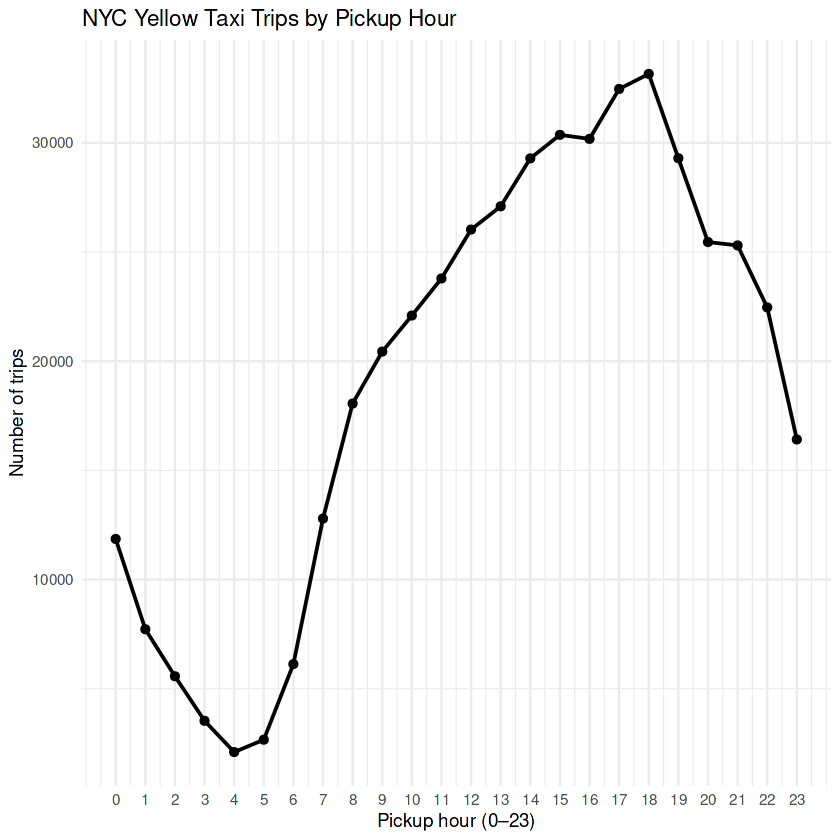

In [17]:
ggplot(trips_by_hour, aes(x = pickup_hour, y = Trips)) +
  geom_line(linewidth = 0.8) +
  geom_point(size = 1.8) +
  scale_x_continuous(breaks = 0:23) +
  labs(
    title = "NYC Yellow Taxi Trips by Pickup Hour",
    x = "Pickup hour (0–23)",
    y = "Number of trips"
  ) +
  theme_minimal()

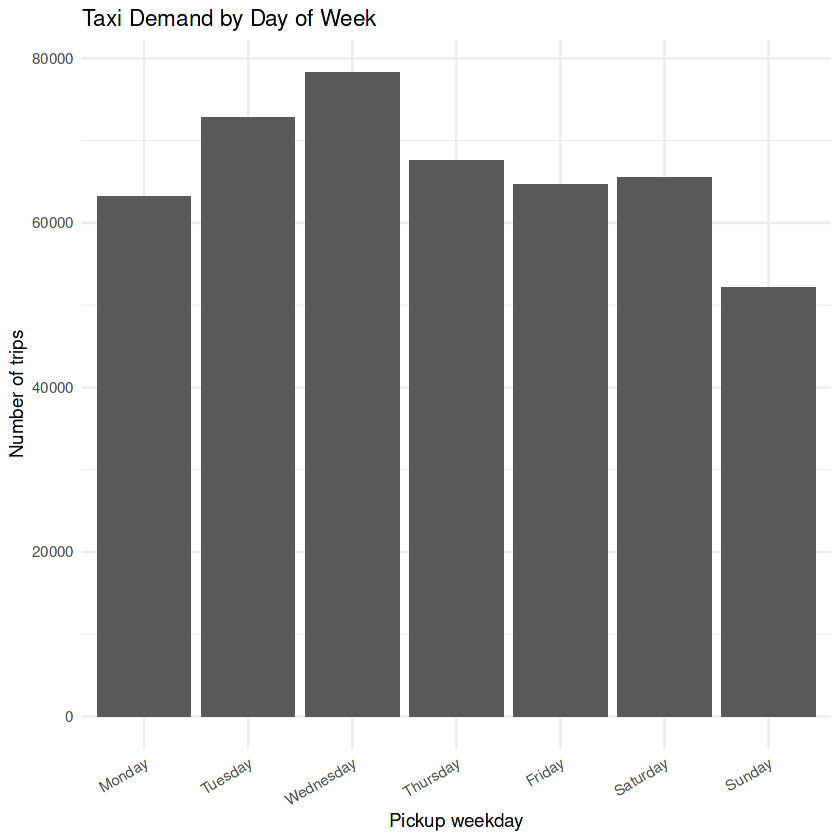

In [18]:
ggplot(trips_by_weekday, aes(x = pickup_weekday, y = Trips)) +
  geom_col() +
  labs(
    title = "Taxi Demand by Day of Week",
    x = "Pickup weekday",
    y = "Number of trips"
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))

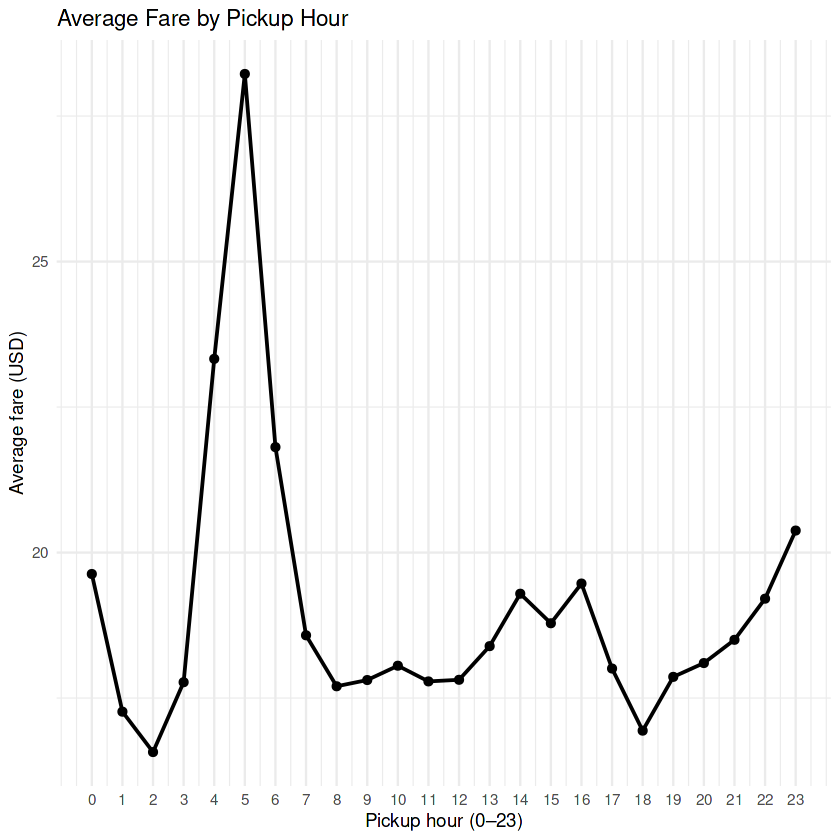

In [19]:
ggplot(trips_by_hour, aes(x = pickup_hour, y = Average_Fare)) +
  geom_line(linewidth = 0.8) +
  geom_point(size = 1.8) +
  scale_x_continuous(breaks = 0:23) +
  labs(
    title = "Average Fare by Pickup Hour",
    x = "Pickup hour (0–23)",
    y = "Average fare (USD)"
  ) +
  theme_minimal()

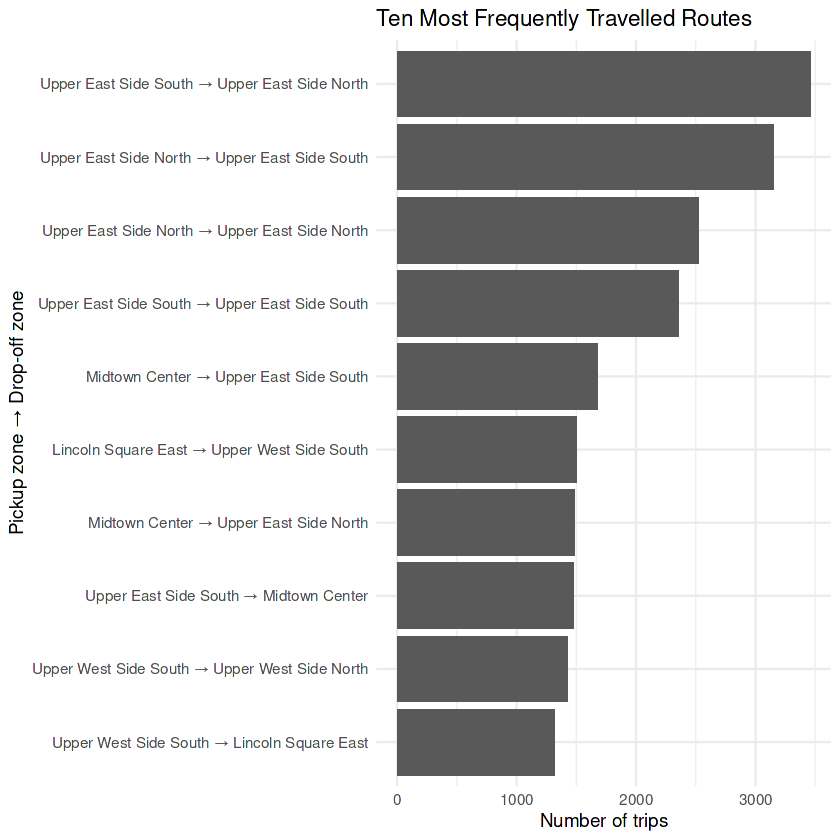

In [20]:
ggplot(top_routes, aes(x = reorder(paste(PU_Zone, "→", DO_Zone), Trips), y = Trips)) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Ten Most Frequently Travelled Routes",
    x = "Pickup zone → Drop-off zone",
    y = "Number of trips"
  ) +
  theme_minimal()

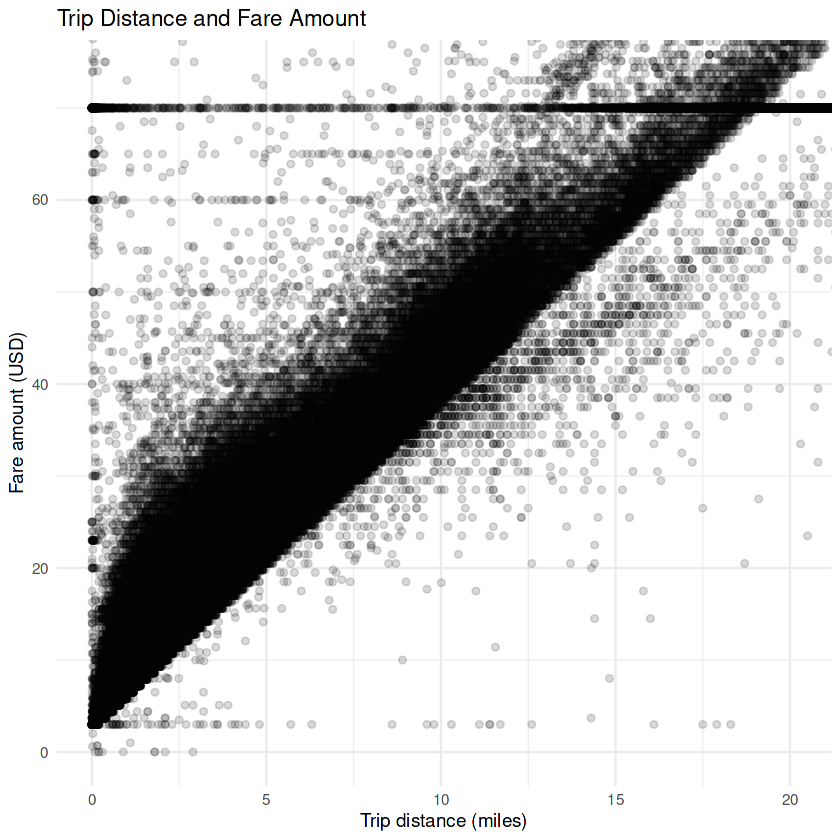

In [21]:
ggplot(trips_joined, aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.15) +
  coord_cartesian(xlim = c(0, quantile(trips_joined$trip_distance, 0.99, na.rm = TRUE)),
                  ylim = c(0, quantile(trips_joined$fare_amount, 0.99, na.rm = TRUE))) +
  labs(
    title = "Trip Distance and Fare Amount",
    x = "Trip distance (miles)",
    y = "Fare amount (USD)"
  ) +
  theme_minimal()

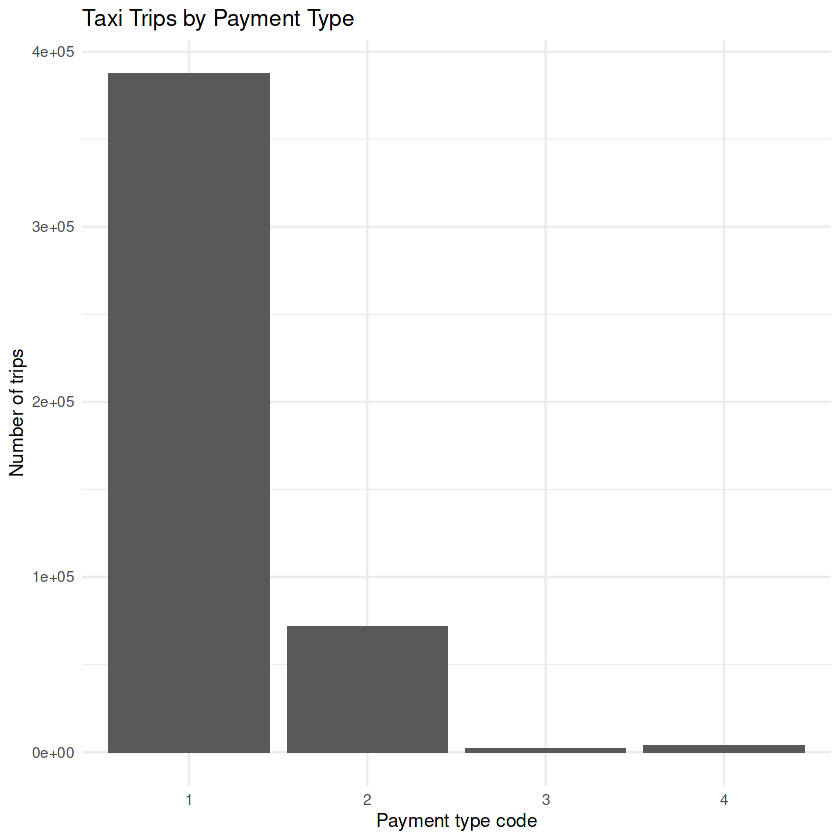

In [22]:
payment_summary <- trips_joined[, .(Trips = .N), by = payment_type]
ggplot(payment_summary, aes(x = factor(payment_type), y = Trips)) +
  geom_col() +
  labs(
    title = "Taxi Trips by Payment Type",
    x = "Payment type code",
    y = "Number of trips"
  ) +
  theme_minimal()

## 8. Functional Programming, Vectorization and data.table

Equivalent operations are implemented using base R, `lapply()` / `purrr::map()`, vectorized operations and `data.table`. The examples calculate trip counts by pickup hour. Benchmarking uses the same subset and produces actual timing results in the current runtime.

In [23]:
# Use a moderate benchmark sample so comparisons finish promptly
set.seed(123)
BENCH_ROWS <- min(100000L, nrow(trips_joined))
bench_data <- as.data.frame(trips_joined[sample.int(nrow(trips_joined), BENCH_ROWS)])

# Base R table implementation
base_hour_counts <- function(d) {
  as.data.frame(table(d$pickup_hour), stringsAsFactors = FALSE)
}

# Vectorized tabulation implementation
vectorized_hour_counts <- function(d) {
  counts <- tabulate(d$pickup_hour + 1L, nbins = 24L)
  data.frame(pickup_hour = 0:23, Trips = counts)
}

# data.table grouping implementation
datatable_hour_counts <- function(d) {
  as.data.table(d)[, .(Trips = .N), by = pickup_hour][order(pickup_hour)]
}

# Functional approach: lapply over hour partitions
lapply_hour_counts <- function(d) {
  hour_groups <- split(d, d$pickup_hour)
  counts <- lapply(hour_groups, nrow)
  data.frame(
    pickup_hour = as.integer(names(counts)),
    Trips = as.integer(unlist(counts)),
    row.names = NULL
  )
}

# purrr::map over hour partitions
purrr_hour_counts <- function(d) {
  hour_groups <- split(d, d$pickup_hour)
  counts <- purrr::map_int(hour_groups, nrow)
  data.frame(
    pickup_hour = as.integer(names(counts)),
    Trips = as.integer(counts),
    row.names = NULL
  )
}

# Validate key totals before benchmarking
cat("Benchmark rows:", nrow(bench_data), "\n")
cat("Vectorized count total:", sum(vectorized_hour_counts(bench_data)$Trips), "\n")
cat("data.table count total:", sum(datatable_hour_counts(bench_data)$Trips), "\n")

Benchmark rows: 100000 
Vectorized count total: 100000 
data.table count total: 100000 


In [24]:
# Compare execution times using microbenchmark
benchmark_results <- microbenchmark(
  Base_R = base_hour_counts(bench_data),
  Vectorized = vectorized_hour_counts(bench_data),
  lapply = lapply_hour_counts(bench_data),
  purrr_map = purrr_hour_counts(bench_data),
  data_table = datatable_hour_counts(bench_data),
  times = 5L
)

benchmark_results

expr,time
<fct>,<dbl>
data_table,10622567
Vectorized,4827355
Base_R,9487206
Base_R,11219938
lapply,48040080
lapply,53737774
purrr_map,47024155
data_table,6504719
Vectorized,973748


In [25]:
# Summarize benchmark timings in milliseconds
benchmark_summary <- as.data.frame(summary(benchmark_results))
benchmark_summary[, c("expr", "min", "median", "mean", "max")]

expr,min,median,mean,max
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Base_R,8453.882,8564.091,9241.352,11219.938
Vectorized,866.488,948.356,1710.973,4827.355
lapply,48040.080,49456.518,50143.519,53737.774
purrr_map,47024.155,51159.361,50392.930,53758.121
data_table,6497.354,6635.014,7414.992,10622.567


### Functional Programming and Performance Interpretation

`lapply()` and `purrr::map()` are useful when applying the same operation to multiple groups or objects and can make repeated tasks easier to organize. Vectorized functions such as `tabulate()` avoid explicit R-level loops for simple counting. `data.table` is designed for efficient grouping and aggregation on large tabular datasets. Use the benchmark table above as experimental evidence; timings depend on the Colab runtime, sample size and current system load.

## 9. Sequential vs Parallel Processing

The cleaned records are partitioned by pickup weekday. The same revenue summary is executed sequentially and in parallel using `foreach` and `doParallel`. Parallel execution can have setup and data-transfer overhead, so it is not guaranteed to be faster for every task.

In [26]:
# Partition the records by weekday
parallel_input <- as.data.table(trips_joined)
weekday_partitions <- split(parallel_input, parallel_input$pickup_weekday, drop = TRUE)

# Define identical work for each partition
summarize_partition <- function(d) {
  as.data.table(d)[, .(
    Trips = .N,
    Total_Revenue = sum(total_amount, na.rm = TRUE),
    Average_Fare = mean(fare_amount, na.rm = TRUE)
  ), by = pickup_weekday]
}

# Sequential execution
seq_time <- system.time({
  sequential_results <- rbindlist(lapply(weekday_partitions, summarize_partition), fill = TRUE)
})

seq_time

   user  system elapsed 
  0.078   0.000   0.042 

In [27]:
# Parallel execution with foreach and doParallel
available_cores <- parallel::detectCores(logical = TRUE)
n_cores <- max(1L, min(4L, available_cores - 1L))
cl <- parallel::makeCluster(n_cores)
doParallel::registerDoParallel(cl)

par_time <- system.time({
  parallel_results <- foreach(
    part = weekday_partitions,
    .combine = function(x, y) data.table::rbindlist(list(x, y), fill = TRUE),
    .packages = "data.table",
    .export = "summarize_partition"
  ) %dopar% {
    data.table::as.data.table(part)[, .(
      Trips = .N,
      Total_Revenue = sum(total_amount, na.rm = TRUE),
      Average_Fare = mean(fare_amount, na.rm = TRUE)
    ), by = pickup_weekday]
  }
})

parallel::stopCluster(cl)
foreach::registerDoSEQ()

cat("Cores used:", n_cores, "\n")
cat("Sequential elapsed seconds:", unname(seq_time["elapsed"]), "\n")
cat("Parallel elapsed seconds:", unname(par_time["elapsed"]), "\n")

Cores used: 3 
Sequential elapsed seconds: 0.042 
Parallel elapsed seconds: 0.983 


In [28]:
# Calculate speedup and compare results
seq_elapsed <- as.numeric(seq_time["elapsed"])
par_elapsed <- as.numeric(par_time["elapsed"])
speedup <- if (par_elapsed > 0) seq_elapsed / par_elapsed else NA_real_

parallel_comparison <- data.frame(
  Method = c("Sequential", "Parallel"),
  Elapsed_Seconds = c(seq_elapsed, par_elapsed),
  Cores = c(1L, n_cores)
)

parallel_comparison
cat("Speedup (sequential / parallel):", round(speedup, 3), "x\n")

# Compare overall totals to ensure the two approaches perform equivalent work
cat("Sequential trip count:", sum(sequential_results$Trips), "\n")
cat("Parallel trip count:", sum(parallel_results$Trips), "\n")

Method,Elapsed_Seconds,Cores
<chr>,<dbl>,<int>
Sequential,0.042,1
Parallel,0.983,3


Speedup (sequential / parallel): 0.043 x
Sequential trip count: 464266 
Parallel trip count: 464266 


### Interpreting Parallel Results

A speedup above 1 means the parallel version finished faster in this run; a speedup below 1 means it was slower. Parallel overhead includes worker startup, data transfer and result combination. Because each weekday partition may be relatively small and the runtime has a limited number of cores, parallel processing may not outperform sequential execution. Report the observed values rather than assuming parallel execution is always better.

## 10. Memory and Scalability Considerations

This section compares the approximate object sizes of the selected data objects. `object.size()` is an estimate of in-memory R object size and does not measure peak memory consumed during an operation.

In [29]:
memory_summary <- data.frame(
  Object = c("trips_raw", "trips_clean", "trips_joined", "bench_data"),
  Approx_Memory_MB = c(
    as.numeric(object.size(trips_raw)),
    as.numeric(object.size(trips_clean)),
    as.numeric(object.size(trips_joined)),
    as.numeric(object.size(bench_data))
  ) / (1024^2)
)

memory_summary$Approx_Memory_MB <- round(memory_summary$Approx_Memory_MB, 2)
memory_summary

Object,Approx_Memory_MB
<chr>,<dbl>
trips_raw,361.90
trips_clean,42.51
trips_joined,63.80
bench_data,13.77


## 11. Critical Analysis

Use the benchmark and parallel comparison outputs to support the answers below.

1. **Best execution performance:** Identify the fastest method in `benchmark_summary` based on median execution time. Results can vary by runtime and data size.
2. **Benefits of data.table:** It supports fast grouping, filtering, joins and aggregations, and can update columns by reference to reduce unnecessary copies.
3. **When functional programming is preferable:** `lapply()` and `purrr::map()` are useful for repeating a common operation over lists, groups or multiple objects while keeping code organized.
4. **When vectorized operations are preferable:** Built-in vectorized operations are often efficient for straightforward element-wise calculations and counting.
5. **Parallel improvement:** Use the measured sequential and parallel elapsed times and calculated speedup.
6. **Does parallel always run faster?** No. Startup and communication overhead can outweigh the benefit for small tasks or limited partitions.
7. **Trade-offs:** Faster methods may be less familiar; additional copies and parallel workers may increase memory usage. Readability and maintainability also matter.
8. **Recommendation:** For large tabular data, use `data.table` for core data processing, vectorized operations for simple transformations, functional tools for repeated workflows, and parallel processing only when the workload is large enough to justify its overhead.

## 12. Conclusion

This experiment develops an end-to-end transportation analytics workflow in R using NYC Yellow Taxi Trip Records and the official Taxi Zone Lookup Table. The data is inspected, cleaned, enriched with temporal attributes, and joined with pickup and drop-off zone information.

Transportation patterns are analysed using `data.table`, and visualizations are created using `ggplot2`. Alternative implementations using base R, functional programming, vectorized operations and `data.table` are benchmarked. Sequential and parallel versions of a partitioned summary are also compared using `foreach` and `doParallel`, with speedup calculated from observed execution times.

The experiment demonstrates that the most suitable approach depends on dataset size, operation type, memory availability, code readability and parallel overhead. Final recommendations should be supported by the benchmark results produced by the executed notebook.